# B4 — Konvolusi dan Penapisan Spasial

Evaluasi Praktikum P1–P4 Computer Vision
SIMUTEH — Klasifikasi Kualitas Daun Teh

# 4.1 Lembar Hitung Manual

In [49]:
# Perhitungan Konvolusi dan Padding
# Matriks citra P
P = np.array([
    [52, 55, 61, 58],
    [59, 255, 64, 60],
    [62, 60, 0, 57],
    [58, 61, 59, 63]
], dtype=float)

# Kernel rerata 3x3
kernel_rerata = np.ones((3, 3)) / 9

# Kernel Gaussian 3x3
kernel_gaussian = np.array([
    [1, 2, 1],
    [2, 4, 2],
    [1, 2, 1]
], dtype=float) / 16

# Menghitung keluaran 2x2 tanpa padding
hasil_rerata = np.zeros((2, 2))
hasil_gaussian = np.zeros((2, 2))
hasil_median = np.zeros((2, 2))

for y in range(2):
    for x in range(2):
        area = P[y:y+3, x:x+3]

        hasil_rerata[y, x] = np.sum(area * kernel_rerata)
        hasil_gaussian[y, x] = np.sum(area * kernel_gaussian)
        hasil_median[y, x] = np.median(area)

print("A. HASIL PENAPISAN 3x3")
print("\nRerata:")
print(np.round(hasil_rerata, 2))

print("\nGaussian:")
print(np.round(hasil_gaussian, 2))

print("\nMedian:")
print(hasil_median)


# B. Kernel penajaman pada matriks Q
Q = np.array([
    [70, 72, 75],
    [74, 120, 78],
    [73, 76, 79]
], dtype=float)

kernel_tajam = np.array([
    [0, -1, 0],
    [-1, 5, -1],
    [0, -1, 0]
], dtype=float)

hasil_tajam = np.sum(Q * kernel_tajam)
hasil_clipping = np.clip(hasil_tajam, 0, 255)

print("\nB. HASIL KERNEL PENAJAMAN")
print("Sebelum clipping:", hasil_tajam)
print("Setelah clipping:", hasil_clipping)


# C. Padding satu piksel
baris = np.array([12, 30, 45, 70])

zero = np.pad(baris, (1, 1), mode="constant")
replicate = np.pad(baris, (1, 1), mode="edge")
reflect = np.pad(baris, (1, 1), mode="reflect")

print("\nC. HASIL PADDING")
print("Zero padding :", zero)
print("Replicate    :", replicate)
print("Reflect      :", reflect)

# Rerata 1x3 pada piksel pertama
print("\nRerata piksel pertama:")
print("Zero padding :", np.mean(zero[0:3]))
print("Replicate    :", np.mean(replicate[0:3]))
print("Reflect      :", np.mean(reflect[0:3]))

A. HASIL PENAPISAN 3x3

Rerata:
[[74.22 74.44]
 [75.33 75.44]]

Gaussian:
[[104.44  77.38]
 [ 77.25  57.44]]

Median:
[[60. 60.]
 [60. 60.]]

B. HASIL KERNEL PENAJAMAN
Sebelum clipping: 300.0
Setelah clipping: 255.0

C. HASIL PADDING
Zero padding : [ 0 12 30 45 70  0]
Replicate    : [12 12 30 45 70 70]
Reflect      : [30 12 30 45 70 45]

Rerata piksel pertama:
Zero padding : 14.0
Replicate    : 18.0
Reflect      : 24.0


# 4.2 Verifikasi Kovolusi Manual

In [50]:
# Verifikasi Konvolusi Manual
import time

def konvolusi(img, k):
    kh, kw = k.shape
    ph, pw = kh // 2, kw // 2

    pad = np.pad(
        img.astype(float),
        ((ph, ph), (pw, pw)),
        mode="edge"
    )

    out = np.zeros(img.shape)

    for y in range(img.shape[0]):
        for x in range(img.shape[1]):
            out[y, x] = np.sum(
                pad[y:y+kh, x:x+kw] * k
            )

    return np.clip(np.round(out), 0, 255).astype(np.uint8)


def konvolusi_sejati(img, k):
    # Kernel dibalik 180 derajat
    return konvolusi(img, np.flip(k))


# Menggunakan citra bersih teh_041
nama = "teh_041.png"

bersih = cv2.imread(
    os.path.join(DATA_DIR, "bersih", nama)
)

bersih = cv2.cvtColor(bersih, cv2.COLOR_BGR2GRAY)

# Kernel yang diuji
kernel = {
    "Rerata": np.ones((3, 3)) / 9,
    "Asimetris": np.array([
        [1, 0, -1],
        [2, 0, -2],
        [1, 0, -1]
    ], dtype=float)
}

for nm, k in kernel.items():

    # Konvolusi manual
    t0 = time.perf_counter()
    a = konvolusi(bersih, k)
    t_manual = time.perf_counter() - t0

    # OpenCV filter2D
    t0 = time.perf_counter()
    b = cv2.filter2D(
        bersih,
        -1,
        k,
        borderType=cv2.BORDER_REPLICATE
    )
    t_cv = time.perf_counter() - t0

    # Konvolusi sejati
    c = konvolusi_sejati(bersih, k)

    beda = np.abs(
        a.astype(int) - b.astype(int)
    ).max()

    beda2 = np.abs(
        c.astype(int) - b.astype(int)
    ).max()

    print(f"\nKernel: {nm}")
    print(f"Selisih manual dengan OpenCV : {beda}")
    print(f"Selisih konvolusi sejati     : {beda2}")
    print(f"Waktu manual                 : {t_manual*1000:.2f} ms")
    print(f"Waktu OpenCV                 : {t_cv*1000:.2f} ms")


Kernel: Rerata
Selisih manual dengan OpenCV : 0
Selisih konvolusi sejati     : 0
Waktu manual                 : 2296.36 ms
Waktu OpenCV                 : 0.51 ms

Kernel: Asimetris
Selisih manual dengan OpenCV : 0
Selisih konvolusi sejati     : 255
Waktu manual                 : 2037.93 ms
Waktu OpenCV                 : 0.37 ms


# 4.3 Tiga Penapis dan dua jenis derau

HASIL PERBANDINGAN PENAPIS


,derau,penapis,PSNR_dB,waktu_ms,KB
0,gauss_10,tanpa,28.11,0.00,4.37
1,gauss_10,rerata_3,36.79,0.28,6.83
2,gauss_10,rerata_5,37.22,0.62,6.67
3,gauss_10,gauss_5,37.56,1.56,6.96
4,gauss_10,median_3,35.48,0.44,6.92
5,gauss_10,median_5,38.36,2.11,7.86
6,gauss_10,median_9,38.18,19.98,8.34
7,gauss_20,tanpa,22.12,0.00,2.46
8,gauss_20,rerata_3,31.41,0.11,5.38
9,gauss_20,rerata_5,34.27,0.14,6.05


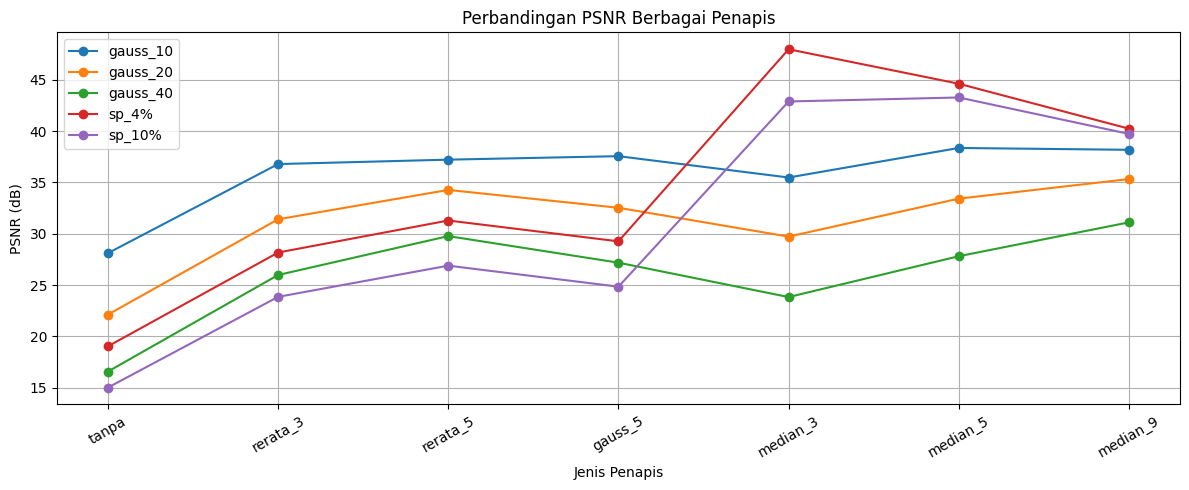

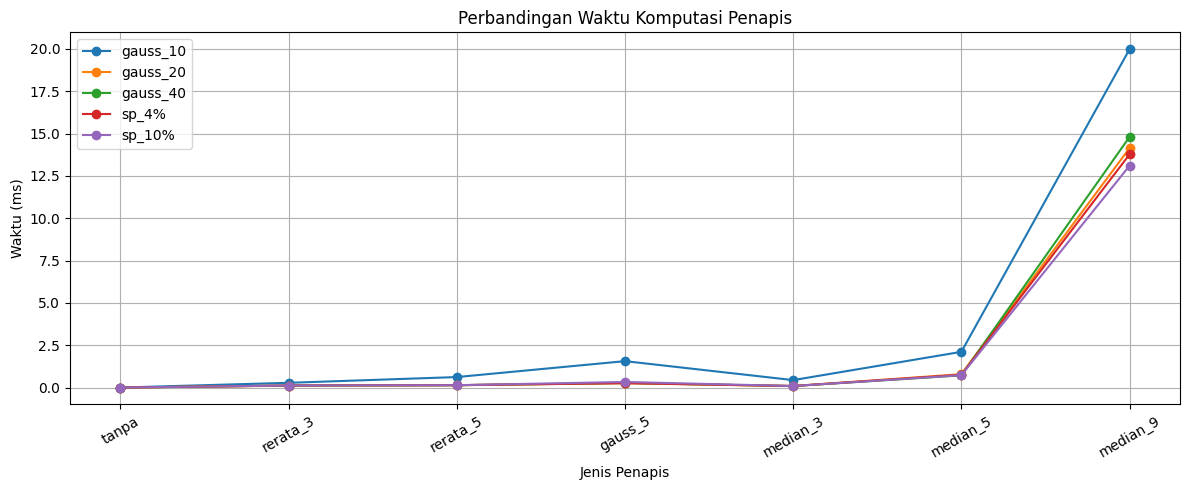

In [51]:
# Perbandingan Penapis dan Jenis Derau
import pandas as pd

rng = np.random.default_rng(42)

# Fungsi pembangkit derau Gaussian
def derau_gauss(img, sd):
    return np.clip(
        img.astype(float) + rng.normal(0, sd, img.shape),
        0, 255
    ).astype(np.uint8)

# Fungsi pembangkit derau garam-merica
def derau_sp(img, p):
    out = img.copy()
    m = rng.random(img.shape)
    out[m < p / 2] = 0
    out[m > 1 - p / 2] = 255
    return out

# Fungsi pengukuran waktu
def ukur_waktu(f, x, ulang=20):
    t = []
    for _ in range(ulang):
        t0 = time.perf_counter()
        f(x)
        t.append(time.perf_counter() - t0)
    return 1000 * np.mean(t)

# Citra acuan
nama = "teh_041.png"

bersih = cv2.imread(
    os.path.join(DATA_DIR, "bersih", nama)
)
bersih = cv2.cvtColor(bersih, cv2.COLOR_BGR2GRAY)

md = cv2.imread(
    os.path.join(DATA_DIR, "mask_daun", nama), 0
)
mb = cv2.imread(
    os.path.join(DATA_DIR, "mask_bercak", nama), 0
)

# Membuat lima jenis derau
derau = {
    "gauss_10": derau_gauss(bersih, 10),
    "gauss_20": derau_gauss(bersih, 20),
    "gauss_40": derau_gauss(bersih, 40),
    "sp_4%": derau_sp(bersih, 0.04),
    "sp_10%": derau_sp(bersih, 0.10)
}

# Enam jenis penapis
penapis = {
    "rerata_3": lambda x: cv2.blur(x, (3, 3)),
    "rerata_5": lambda x: cv2.blur(x, (5, 5)),
    "gauss_5": lambda x: cv2.GaussianBlur(x, (5, 5), 1.0),
    "median_3": lambda x: cv2.medianBlur(x, 3),
    "median_5": lambda x: cv2.medianBlur(x, 5),
    "median_9": lambda x: cv2.medianBlur(x, 9)
}

# Menghitung PSNR, waktu, dan KB
baris = []

for dn, d in derau.items():

    baris.append([
        dn,
        "tanpa",
        cv2.PSNR(bersih, d),
        0.0,
        kontras_bercak(d, md, mb)
    ])

    for pn, f in penapis.items():

        out = f(d)

        baris.append([
            dn,
            pn,
            cv2.PSNR(bersih, out),
            ukur_waktu(f, d),
            kontras_bercak(out, md, mb)
        ])

tabel = pd.DataFrame(
    baris,
    columns=["derau", "penapis", "PSNR_dB", "waktu_ms", "KB"]
).round(2)

print("HASIL PERBANDINGAN PENAPIS")
display(tabel)

# Simpan hasil
tabel.to_csv(
    os.path.join(HASIL_DIR, "b4_tabel_penapis.csv"),
    index=False
)

# Grafik PSNR setiap jenis derau
plt.figure(figsize=(12, 5))

for dn in derau.keys():
    data = tabel[tabel["derau"] == dn]
    plt.plot(data["penapis"], data["PSNR_dB"], marker="o", label=dn)

plt.title("Perbandingan PSNR Berbagai Penapis")
plt.xlabel("Jenis Penapis")
plt.ylabel("PSNR (dB)")
plt.xticks(rotation=30)
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

# Grafik waktu komputasi
plt.figure(figsize=(12, 5))

for dn in derau.keys():
    data = tabel[tabel["derau"] == dn]
    plt.plot(data["penapis"], data["waktu_ms"], marker="o", label=dn)

plt.title("Perbandingan Waktu Komputasi Penapis")
plt.xlabel("Jenis Penapis")
plt.ylabel("Waktu (ms)")
plt.xticks(rotation=30)
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

# 4.4 Apakah bercak kecil tetap terjaga?

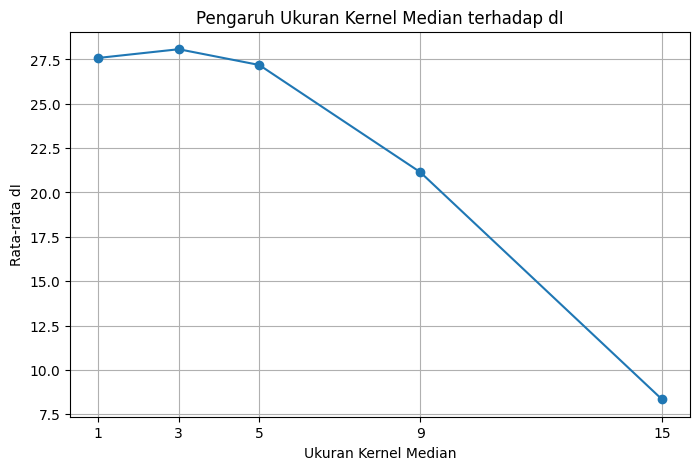

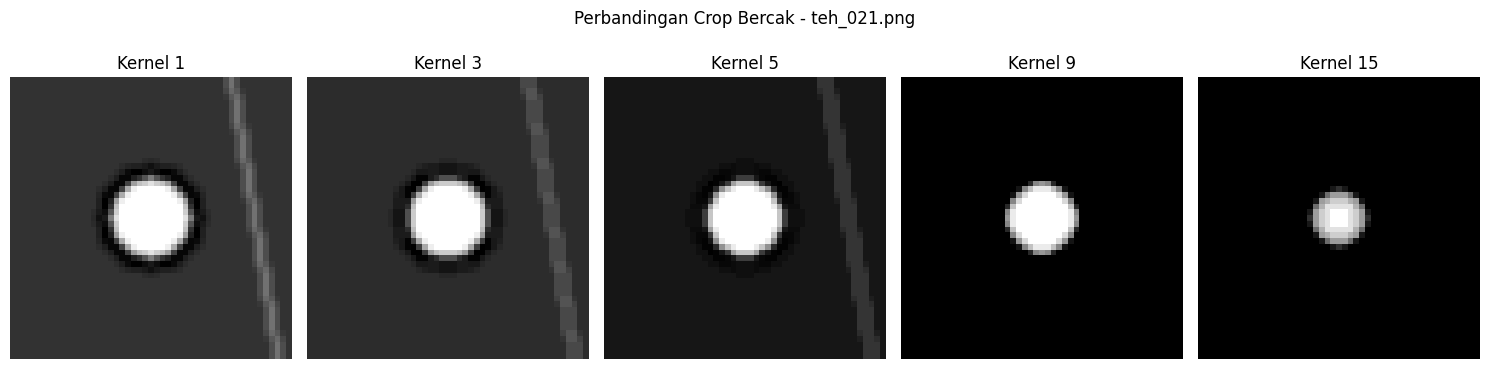

In [53]:
# Pengaruh Ukuran Kernel Median pada Bercak Kecil
def selisih_rerata(kanal, mask_daun, mask_bercak):
    k = kanal.astype(float)
    sehat = (mask_daun > 0) & (mask_bercak == 0)
    bercak = mask_bercak > 0

    return abs(k[bercak].mean() - k[sehat].mean())


# Membaca label citra
label = pd.read_csv(os.path.join(DATA_DIR, "label.csv"))
data_ringan = label[label["kelas"] == "ringan"]

baris = []

# Menghitung dI dan KB pada 20 citra kelas ringan
for nm in data_ringan["nama_file"]:
    g = cv2.imread(os.path.join(DATA_DIR, "bersih", nm), 0)
    md2 = cv2.imread(os.path.join(DATA_DIR, "mask_daun", nm), 0)
    mb2 = cv2.imread(os.path.join(DATA_DIR, "mask_bercak", nm), 0)

    for k in [1, 3, 5, 9, 15]:
        out = g if k == 1 else cv2.medianBlur(g, k)

        dI = selisih_rerata(out, md2, mb2)
        KB = kontras_bercak(out, md2, mb2)

        baris.append([nm, k, dI, KB])

hasil_median = pd.DataFrame(
    baris,
    columns=["nama", "kernel", "dI", "KB"]
)

# Menghitung rata-rata dI setiap ukuran kernel
rata_dI = hasil_median.groupby("kernel")["dI"].mean()

# Grafik dI terhadap ukuran kernel
plt.figure(figsize=(8, 5))
plt.plot(rata_dI.index, rata_dI.values, marker="o")
plt.xticks([1, 3, 5, 9, 15])
plt.xlabel("Ukuran Kernel Median")
plt.ylabel("Rata-rata dI")
plt.title("Pengaruh Ukuran Kernel Median terhadap dI")
plt.grid(True)
plt.show()


# Crop satu bercak untuk perbandingan visual
nm_crop = data_ringan.iloc[0]["nama_file"]

g = cv2.imread(os.path.join(DATA_DIR, "bersih", nm_crop), 0)
mb2 = cv2.imread(os.path.join(DATA_DIR, "mask_bercak", nm_crop), 0)

jumlah, label_komponen, statistik, pusat = cv2.connectedComponentsWithStats(
    (mb2 > 0).astype(np.uint8), 8
)

if jumlah > 1:
    # Memilih bercak dengan luas terbesar
    komponen = 1 + np.argmax(statistik[1:, cv2.CC_STAT_AREA])

    x, y, w, h, luas = statistik[komponen]

    margin = 15
    x1 = max(0, x - margin)
    y1 = max(0, y - margin)
    x2 = min(g.shape[1], x + w + margin)
    y2 = min(g.shape[0], y + h + margin)

    crop_asli = g[y1:y2, x1:x2]

    plt.figure(figsize=(15, 4))

    for i, k in enumerate([1, 3, 5, 9, 15]):
        hasil = crop_asli if k == 1 else cv2.medianBlur(crop_asli, k)

        plt.subplot(1, 5, i + 1)
        plt.imshow(hasil, cmap="gray")
        plt.title(f"Kernel {k}")
        plt.axis("off")

    plt.suptitle(f"Perbandingan Crop Bercak - {nm_crop}")
    plt.tight_layout()
    plt.show()

else:
    print("Bercak tidak ditemukan pada citra yang dipilih.")

# 4.5 Urutan meredam derau dan menajamkan

In [54]:
# Pengaruh Urutan Penajaman dan Peredaman Derau
# Fungsi penajaman (Unsharp Masking)
def unsharp(x, k=1.0):
    blur = cv2.GaussianBlur(x, (5, 5), 1.0)
    return cv2.addWeighted(x, 1 + k, blur, -k, 0)


# Menggunakan citra dengan derau Gaussian standar deviasi 20
noisy = derau["gauss_20"]

# Area latar belakang
latar = md == 0

# Membandingkan dua urutan proses
for nm, redam in {
    "Gaussian": lambda x: cv2.GaussianBlur(x, (5, 5), 1.0),
    "Median": lambda x: cv2.medianBlur(x, 5)
}.items():

    # Penajaman kemudian peredaman
    A = redam(unsharp(noisy))

    # Peredaman kemudian penajaman
    B = unsharp(redam(noisy))

    print(
        f"{nm}: "
        f"tajam->redam PSNR={cv2.PSNR(bersih, A):.2f} "
        f"sigma_latar={A[latar].std():.1f} | "
        f"redam->tajam PSNR={cv2.PSNR(bersih, B):.2f} "
        f"sigma_latar={B[latar].std():.1f}"
    )

Gaussian: tajam->redam PSNR=30.41 sigma_latar=7.8 | redam->tajam PSNR=30.20 sigma_latar=8.2
Median: tajam->redam PSNR=30.14 sigma_latar=8.1 | redam->tajam PSNR=31.09 sigma_latar=7.2


# 4.6 Pengujian pada Citra dengan Derau Sensor Bawaan.

In [57]:
# Pengujian Penapis pada Citra dengan Derau Sensor Bawaan
baris = []

# Mengambil 12 citra: teh_001, teh_006, teh_011, ..., teh_056
daftar_citra = [
    f"teh_{i:03d}.png" for i in range(1, 57, 5)
]

for nm in daftar_citra:

    # Membaca citra dengan derau sensor bawaan
    citra_derau = cv2.imread(
        os.path.join(DATA_DIR, "citra", nm), 0
    )

    # Membaca citra bersih sebagai pembanding
    citra_bersih = cv2.imread(
        os.path.join(DATA_DIR, "bersih", nm), 0
    )

    # Memastikan citra berhasil dibaca
    if citra_derau is None or citra_bersih is None:
        print("Citra tidak ditemukan:", nm)
        continue

    # Penapisan median 5x5
    hasil = cv2.medianBlur(citra_derau, 5)

    # Menghitung PSNR sebelum dan sesudah penapisan
    psnr_sebelum = cv2.PSNR(citra_bersih, citra_derau)
    psnr_sesudah = cv2.PSNR(citra_bersih, hasil)

    baris.append([
        nm,
        psnr_sebelum,
        psnr_sesudah
    ])

hasil_sensor = pd.DataFrame(
    baris,
    columns=["nama_file", "PSNR_sebelum", "PSNR_sesudah"]
).round(2)

print("HASIL PENGUJIAN 12 CITRA DENGAN DERau SENSOR")
display(hasil_sensor)

print("\nRATA-RATA PSNR:")
print("Sebelum penapisan :", round(hasil_sensor["PSNR_sebelum"].mean(), 2), "dB")
print("Sesudah penapisan :", round(hasil_sensor["PSNR_sesudah"].mean(), 2), "dB")

hasil_sensor.to_csv(
    os.path.join(HASIL_DIR, "b4_pengujian_derau_sensor.csv"),
    index=False
)

HASIL PENGUJIAN 12 CITRA DENGAN DERau SENSOR


,nama_file,PSNR_sebelum,PSNR_sesudah
0,teh_001.png,34.16,43.03
1,teh_006.png,32.48,42.22
2,teh_011.png,34.36,43.33
3,teh_016.png,32.82,42.35
4,teh_021.png,28.85,39.24
5,teh_026.png,34.08,42.97
6,teh_031.png,35.22,43.50
7,teh_036.png,31.98,41.63
8,teh_041.png,33.66,41.93
9,teh_046.png,28.88,38.80



RATA-RATA PSNR:
Sebelum penapisan : 32.39 dB
Sesudah penapisan : 41.61 dB
